<a href="https://colab.research.google.com/github/Alexandra1031/Metodos-numericos-l/blob/main/Metodo_de_Neville_MoralesNoriegaAlexandra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#<font color="pink">**Metodo de Neville**

<font color="purple">**Alexandra Morales Noriega**


<font color="purple">**Metodos numericos l**


Se conoce el valor de una funcion $f$ solo en $n+1$ nodos distintos $x_0, x_1,..., x_n$ y se requiere estimar $f(x)$ en un punto $x$ que no esta en la tabla.Para ello se usa el polinomio $P$ que cumple:
$$P(x_k) = f(x_k), \qquad k=0,1,...,n,$$
y se toma $P(x)$ como aproximacion de $f(x)$

El metodo de Neville evalua $P(x)$ directamente, sin calcular los coeficientes del polinomio. Se parte de los datos como aproximaciones de grado cero:
$$Q_{i,0} = f(x_i), \qquad i = 0,1, \dots, n$$
y cada aproximacion de grado $j$ se obtiene combinando dos de grado $j-1$. Para $i=1, \dots, n$ y $j = 1, \dots, i$:
$$Q_{i,j}  = \frac{(x-x_{i-j})\,Q_{i-1,j-1}}{x_i-x_{i-j}}$$
La **solucion final** es $P(x)=Q_{n,n}$

In [14]:
import numpy as np   # arreglos y matrices numéricas
import pandas as pd  # para mostrar la tabla Q con formato
import matplotlib.pyplot as plt  # para graficar

In [15]:
def neville(x, xs, fs):
    """
    Interpolación iterada de Neville (Algoritmo 3.1, Burden).

    ENTRADA: x  -> punto donde se evalúa P
             xs -> nodos x_0, ..., x_n
             fs -> valores f(x_0), ..., f(x_n)
    SALIDA:  Q  -> tabla con P(x) = Q[n, n]
    """
    n = len(xs) - 1                    # n+1 es el número de nodos
    Q = np.zeros((n + 1, n + 1))       # tabla Q inicializada en ceros
    Q[:, 0] = fs                       # primera columna: Q_{i,0} = f(x_i)

    # construyendo la tabla por filas
    for i in range(1, n + 1):          # i = 1, ..., n (fila)
        for j in range(1, i + 1):      # j = 1, ..., i (columna = grado)
            # Fórmula de Neville: combina dos aproximaciones de grado j-1
            Q[i, j] = ((x - xs[i - j]) * Q[i, j - 1]
                       - (x - xs[i]) * Q[i - 1, j - 1]) / (xs[i] - xs[i - j])

    # salida
    return Q

 Ejemplo 2 (Burden, p. 89)

Aproximar $f(1.5)$ con los datos de la Tabla 3.5:

| $x$ | $f(x)$ |
|---|---|
| 1.0 | 0.7651977 |
| 1.3 | 0.6200860 |
| 1.6 | 0.4554022 |
| 1.9 | 0.2818186 |
| 2.2 | 0.1103623 |

In [16]:
x_eval = 1.5                                                 # punto donde se aproxima f
xs = [1.0, 1.3, 1.6, 1.9, 2.2]                               # nodos (Tabla 3.5)
fs = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623] # valores f(x_i)

Q = neville(x_eval, xs, fs)   # se construye la tabla Q

# Se muestra Q como tabla; np.tril conserva solo la parte triangular inferior
tabla = pd.DataFrame(Q, index=xs, columns=[f"Q(i,{j})" for j in range(len(xs))])
tabla.where(np.tril(np.ones_like(Q, dtype=bool))).style.format("{:.7f}", na_rep="")

,"Q(i,0)","Q(i,1)","Q(i,2)","Q(i,3)","Q(i,4)"
1.000000,0.7651977,,,,
1.300000,0.6200860,0.5233449,,,
1.600000,0.4554022,0.5102968,0.5124715,,
1.900000,0.2818186,0.5132634,0.5112857,0.5118127,
2.200000,0.1103623,0.5104270,0.5137361,0.5118302,0.5118200


In [17]:
# La solución final es la última entrada de la diagonal: Q[n, n]
print(f"Solución final: P({x_eval}) = Q[4,4] = {Q[-1, -1]:.7f}")

Solución final: P(1.5) = Q[4,4] = 0.5118200


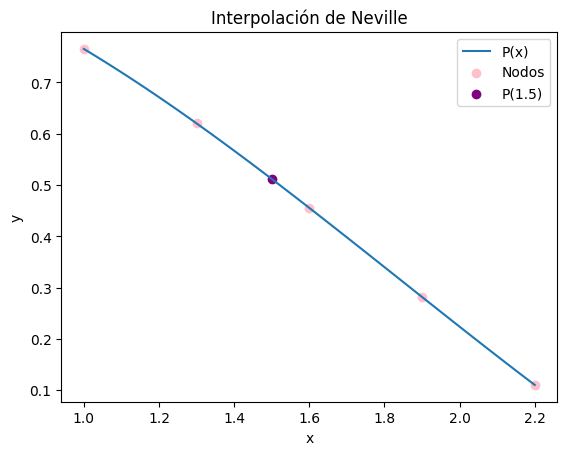

In [23]:
import matplotlib.pyplot as plt

xx = np.linspace(1.0, 2.2, 100)                   # puntos del eje x
P = [neville(t, xs, fs)[-1, -1] for t in xx]      # P(t) para cada punto

plt.plot(xx, P, label="P(x)")                     # curva del polinomio
plt.scatter(xs, fs, color="pink", label="Nodos")   # datos originales
plt.scatter(x_eval, Q[-1, -1], color="purple", label="P(1.5)")  # punto aproximado
plt.title("Interpolación de Neville")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

**Gráfica del polinomio:** la curva azul es el polinomio de interpolación $P(x)$ de grado 4, evaluado en muchos puntos con el método de Neville. Pasa exactamente por los cinco nodos (en rosa), y el punto morado marca la aproximación $P(1.5)=Q_{4,4}$.

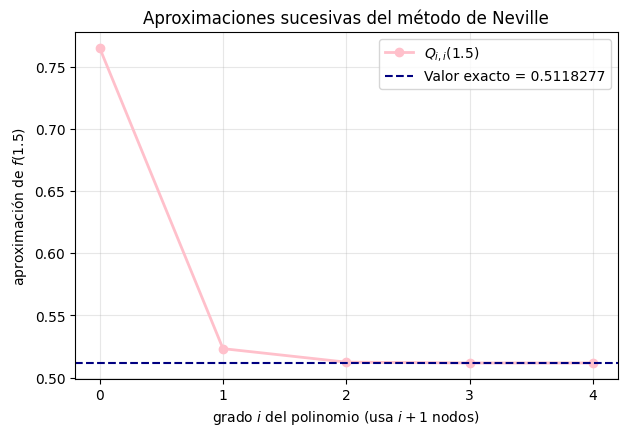

In [22]:
import matplotlib.pyplot as plt
from scipy.special import j0          # función de Bessel de orden cero

exacto = j0(1.5)                      # valor exacto de f(1.5)
grados = range(len(xs))               # grados 0, 1, ..., 4
diagonal = np.diag(Q)                 # Q[i,i]: aproximación de grado i

plt.figure(figsize=(7, 4.5))
plt.plot(grados, diagonal, "o-", color="pink", linewidth=2,
         label=r"$Q_{i,i}(1.5)$")                                  # aproximaciones sucesivas
plt.axhline(exacto, color="navy", linestyle="--",
            label=f"Valor exacto = {exacto:.7f}")                  # línea del valor exacto
plt.title("Aproximaciones sucesivas del método de Neville")
plt.xlabel(r"grado $i$ del polinomio (usa $i+1$ nodos)")
plt.ylabel(r"aproximación de $f(1.5)$")
plt.xticks(grados)                    # solo enteros en el eje x
plt.grid(alpha=0.3)
plt.legend()
plt.show()

**Convergencia:** En esta gráfica se muestra cómo las aproximaciones $Q_{i,i}(1.5)$, de grado creciente, se acercan al valor exacto de $f(1.5)$.

###Verificación

La función del ejemplo es la función de Bessel de primera clase de orden cero, $J_0(x)$. Se compara la solución con su valor exacto en $x=1.5$.

In [20]:
from scipy.special import j0   # función de Bessel de orden cero

exacto = j0(1.5)                      # valor exacto de f(1.5)
aprox = Q[-1, -1]                     # solución final Q[4,4]

print(f"Valor exacto J0(1.5)  = {exacto:.7f}")
print(f"Aproximación Q[4,4]   = {aprox:.7f}")
print(f"Error absoluto        = {abs(exacto - aprox):.2e}")

Valor exacto J0(1.5)  = 0.5118277
Aproximación Q[4,4]   = 0.5118200
Error absoluto        = 7.68e-06


###Conclusión

La tabla obtenida coincide con la Tabla 3.6 del libro. La **solución final** es

$$P(1.5) \approx Q_{4,4} = 0.5118200$$

Al compararla con el valor exacto $J_0(1.5)=0.5118277$, el error absoluto es del orden de $10^{-6}$, por lo que el método de Neville produjo una aproximación muy precisa con cinco nodos.